# SecureCAN AI - exploring the HCRL Car-Hacking dataset

This notebook is the "look before you code" step. Every design decision in
`src/securecan/` traces back to something measured here, and two of the cells
below found bugs that had already silently corrupted the results.

The dataset is the **Korea University HCRL Car-Hacking Dataset**: real CAN
traffic captured from the OBD-II port of a **Hyundai YF Sonata**, with attacks
injected on a real bus (not simulated).

Run order: `tools/fetch_dataset.py` -> `python -m securecan.parse` -> this notebook.

---

## What we need to find out

1. What do the raw files actually look like? (there is a parsing trap)
2. How imbalanced are the classes?
3. Do the attacks look different in a way a tiny model could learn?
4. Where in each file do the attacks live? (this one matters enormously)

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from securecan import features as F, dataset, parse

PROCESSED = ROOT / "data" / "processed"
RAW = ROOT / "data" / "raw"
CLASS_NAMES = ["Normal", "DoS", "Fuzzy", "Gear", "RPM"]

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
print("root:", ROOT)

root: D:\Embedded project


## 1. The raw files, and the trap in them

The attack CSVs have **no header row**, and the number of columns is not
constant. A frame with `DLC=8` has 8 data bytes then the flag; a frame with
`DLC=2` has only 2 data bytes then the flag. So the flag is **not** in a fixed
column -- it is always *last*, at position `3 + DLC`.

Writing the parser against a fixed column index would read a data byte as the
label. That is a silent corruption: it would not crash, it would just mislabel
some frames and quietly cap the achievable accuracy.

In [2]:
print("=== DoS_dataset.csv (attack format: no header, flag is LAST) ===")
with open(RAW / "DoS_dataset.csv") as fh:
    for _ in range(4):
        print("  ", fh.readline().rstrip())

# find a short-DLC line to show the column shift
with open(RAW / "DoS_dataset.csv") as fh:
    for line in fh:
        if int(line.split(",")[2]) < 8:
            print("\n   a DLC<8 row -- note it is SHORTER:")
            print("  ", line.rstrip())
            break

print("\n=== normal_run_data.txt (completely different format!) ===")
with open(RAW / "normal_run_data.txt") as fh:
    for _ in range(3):
        print("  ", fh.readline().rstrip())

=== DoS_dataset.csv (attack format: no header, flag is LAST) ===
   1478198376.389427,0316,8,05,21,68,09,21,21,00,6f,R
   1478198376.389636,018f,8,fe,5b,00,00,00,3c,00,00,R
   1478198376.389864,0260,8,19,21,22,30,08,8e,6d,3a,R
   1478198376.390096,02a0,8,64,00,9a,1d,97,02,bd,00,R

   a DLC<8 row -- note it is SHORTER:
   1478198376.409484,05f0,2,01,00,R

=== normal_run_data.txt (completely different format!) ===
   Timestamp: 1479121434.850202        ID: 0350    000    DLC: 8    05 28 84 66 6d 00 00 a2
   Timestamp: 1479121434.850423        ID: 02c0    000    DLC: 8    14 00 00 00 00 00 00 00
   Timestamp: 1479121434.850977        ID: 0430    000    DLC: 8    00 00 00 00 00 00 00 00


The normal capture is a candump-style text log (`Timestamp: ... ID: 0316 ... DLC: 8  05 21 ...`),
not CSV at all. `parse.py` therefore has two readers, and `tests/test_parse.py`
pins the short-DLC case so this can never regress.

In [3]:
# Load everything parsed. Each .npz is one capture.
caps = {}
for p in sorted(PROCESSED.glob("*.npz")):
    caps[p.stem] = np.load(p)

total = 0
print(f"{'capture':<18} {'frames':>10} {'span s':>9} {'frames/s':>9}  classes")
for name, d in caps.items():
    ts, lab = d["ts"], d["label"]
    span = ts[-1] - ts[0]
    cnt = np.bincount(lab, minlength=5)
    present = " ".join(f"{CLASS_NAMES[i]}={cnt[i]:,}" for i in range(5) if cnt[i])
    print(f"{name:<18} {len(ts):>10,} {span:>9.1f} {len(ts)/span:>9,.0f}  {present}")
    total += len(ts)
print(f"\n{total:,} frames in total")

capture                frames    span s  frames/s  classes
DoS_dataset         3,665,771    2832.7     1,294  Normal=3,078,250 DoS=587,521
Fuzzy_dataset       3,838,860    5487.2       700  Normal=3,347,013 Fuzzy=491,847


gear_dataset        4,443,142    8019.0       554  Normal=3,845,890 Gear=597,252
normal_run_data       988,871     506.4     1,953  Normal=988,871
RPM_dataset         4,621,702   10179.0       454  Normal=3,966,805 RPM=654,897

17,558,346 frames in total


## 2. Class balance

Normal traffic dominates, which is exactly what a real bus looks like. This is
why **accuracy is a useless metric here** -- a model that always answers
"Normal" would already score very well. We report per-class precision/recall
and the false-positive rate instead.

  Normal   15,226,829   86.72%
  DoS         587,521    3.35%
  Fuzzy       491,847    2.80%
  Gear        597,252    3.40%
  RPM         654,897    3.73%

  attack frames overall: 13.28%
  always-answer-Normal accuracy would be 86.72%


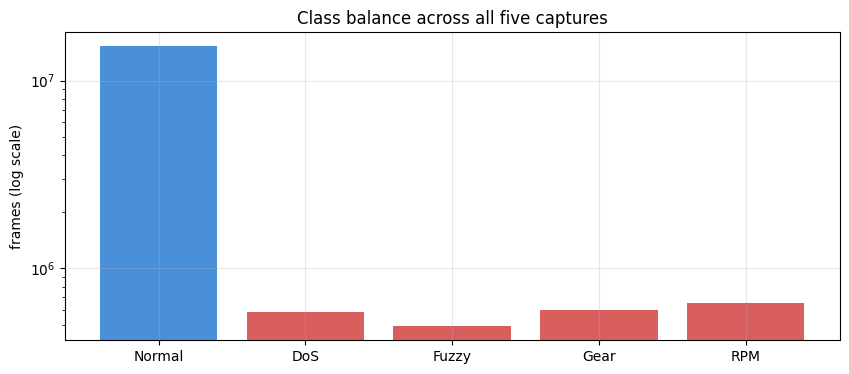

In [4]:
all_lab = np.concatenate([d["label"] for d in caps.values()])
cnt = np.bincount(all_lab, minlength=5)

for i, n in enumerate(cnt):
    print(f"  {CLASS_NAMES[i]:<8} {n:>10,}  {100*n/cnt.sum():>6.2f}%")
print(f"\n  attack frames overall: {100*(1 - cnt[0]/cnt.sum()):.2f}%")
print(f"  always-answer-Normal accuracy would be {100*cnt[0]/cnt.sum():.2f}%")

fig, ax = plt.subplots()
ax.bar(CLASS_NAMES, cnt, color=["#4a90d9"] + ["#d95f5f"] * 4)
ax.set_yscale("log")
ax.set_ylabel("frames (log scale)")
ax.set_title("Class balance across all five captures")
plt.show()

## 3. THE BUG THIS NOTEBOOK FOUND: the clean tail

The first full training run reported **99.996% accuracy** and a confusion matrix
with only one non-empty row. The test split contained **2,633,754 frames and
zero attacks**.

The cause is below. HCRL **stopped injecting before each recording ended**, so
the last fifth of every attack file is pure normal traffic. A naive 70/15/15
index split puts the whole test set inside that clean tail.

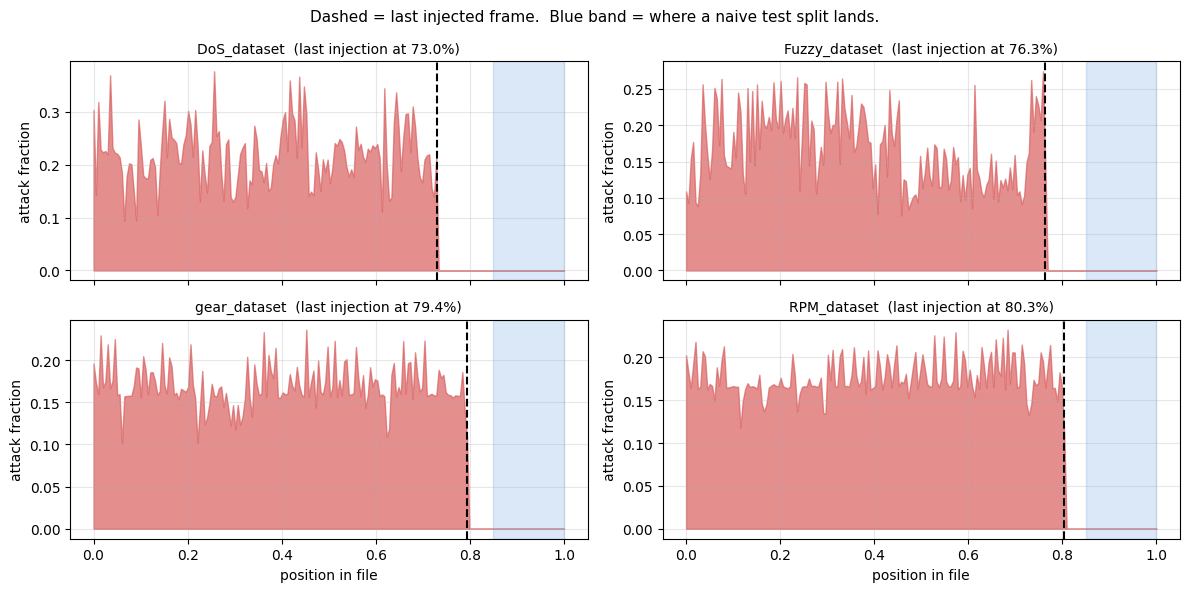

The blue band sits entirely to the RIGHT of every dashed line.
That is the bug, drawn.

  DoS_dataset      injection stops at  73.0%  -> 27.0% clean tail
  Fuzzy_dataset    injection stops at  76.3%  -> 23.7% clean tail
  gear_dataset     injection stops at  79.4%  -> 20.6% clean tail
  RPM_dataset      injection stops at  80.3%  -> 19.7% clean tail


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)

for ax, name in zip(axes.ravel(), ["DoS_dataset", "Fuzzy_dataset",
                                   "gear_dataset", "RPM_dataset"]):
    lab = caps[name]["label"]
    pos = np.linspace(0, 1, len(lab))
    # attack density in 200 bins down the file
    bins = 200
    idx = np.minimum((pos * bins).astype(int), bins - 1)
    dens = np.bincount(idx, weights=(lab != 0), minlength=bins) / \
           np.maximum(np.bincount(idx, minlength=bins), 1)

    last = np.flatnonzero(lab != 0)[-1] / len(lab)
    ax.fill_between(np.linspace(0, 1, bins), dens, color="#d95f5f", alpha=0.7)
    ax.axvline(last, color="k", ls="--", lw=1.5)
    ax.axvspan(0.85, 1.0, color="#4a90d9", alpha=0.2)
    ax.set_title(f"{name}  (last injection at {100*last:.1f}%)", fontsize=10)
    ax.set_ylabel("attack fraction")

axes[1, 0].set_xlabel("position in file")
axes[1, 1].set_xlabel("position in file")
fig.suptitle("Dashed = last injected frame.  Blue band = where a naive test split lands.",
             fontsize=11)
plt.tight_layout()
plt.show()

print("The blue band sits entirely to the RIGHT of every dashed line.")
print("That is the bug, drawn.\n")
for name in ["DoS_dataset", "Fuzzy_dataset", "gear_dataset", "RPM_dataset"]:
    lab = caps[name]["label"]
    last = np.flatnonzero(lab != 0)[-1] / len(lab)
    print(f"  {name:<16} injection stops at {100*last:5.1f}%  "
          f"-> {100*(1-last):4.1f}% clean tail")

### The fix

`dataset.split_slices()` treats each file as two contiguous regions -- the
attack-bearing part and the clean tail -- and splits **each one** 70/15/15 by
time. Every split then sees the same class balance, ordering stays chronological
inside each region, and the clean tail becomes what it actually is: extra real
normal traffic, which makes the false-positive estimate *better*.

Note we did **not** fix this by shuffling. Shuffling would also have produced
attacks in the test set, and a meaningless score: consecutive CAN frames are
strongly correlated, so a shuffled split lets the model memorise neighbours.

In [6]:
for name in ["DoS_dataset", "RPM_dataset"]:
    lab = caps[name]["label"]
    sl = dataset.split_slices(lab)
    print(f"{name}:")
    for split in ("train", "val", "test"):
        n = atk = 0
        for s in sl[split]:
            seg = lab[s]
            n += len(seg)
            atk += int((seg != 0).sum())
        print(f"    {split:<6} {n:>9,} frames   {100*atk/max(n,1):5.2f}% attack")
    print()

DoS_dataset:
    train  2,566,038 frames   15.90% attack
    val      549,866 frames   16.40% attack
    test     549,867 frames   16.23% attack

RPM_dataset:
    train  3,235,190 frames   13.99% attack
    val      693,255 frames   14.90% attack
    test     693,257 frames   14.28% attack



## 4. What the attacks look like on the bus

Now the part that decides whether this project is even possible. If attacks are
statistically indistinguishable from normal traffic, no amount of model is going
to help.

### 4a. Bus load during a DoS flood

DoS uses **ID 0x000**. That is not arbitrary: CAN arbitration is bit-wise and
dominant-0 wins, so an all-zero ID is 11 dominant bits and beats every other
message on the bus. It is the highest-priority frame that exists.

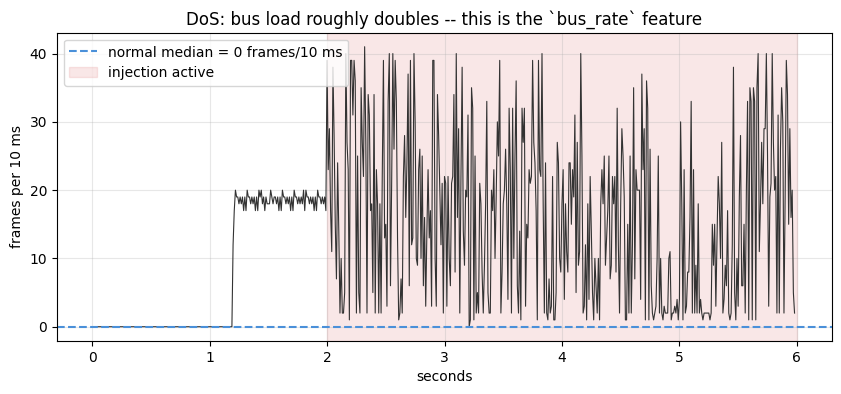

normal   0 frames/10 ms
flooded  41 frames/10 ms


In [7]:
d = caps["DoS_dataset"]
ts, lab = d["ts"], d["label"]

# a 6 s window straddling the first burst
first = np.flatnonzero(lab != 0)[0]
t0 = ts[first] - 2.0
sl = slice(*np.searchsorted(ts, [t0, t0 + 6.0]))

tw, lw = ts[sl] - t0, lab[sl]
edges = np.arange(0, 6.0, 0.010)                 # 10 ms bins = our window
rate, _ = np.histogram(tw, bins=edges)

fig, ax = plt.subplots()
ax.plot(edges[:-1], rate, lw=0.8, color="#333")
ax.axhline(np.median(rate[:150]), color="#4a90d9", ls="--",
           label=f"normal median = {np.median(rate[:150]):.0f} frames/10 ms")
atk_t = tw[lw != 0]
if len(atk_t):
    ax.axvspan(atk_t.min(), atk_t.max(), color="#d95f5f", alpha=0.15,
               label="injection active")
ax.set_xlabel("seconds")
ax.set_ylabel("frames per 10 ms")
ax.set_title("DoS: bus load roughly doubles -- this is the `bus_rate` feature")
ax.legend()
plt.show()

print(f"normal   {np.median(rate[:150]):.0f} frames/10 ms")
print(f"flooded  {rate.max():.0f} frames/10 ms")

### 4b. Spoofing is invisible to bus load

This is the important negative result. Gear and RPM spoofing inject a **real ID
with a fake value**, about once per millisecond. Each injected frame is a
perfectly valid CAN frame -- correct ID, correct DLC, valid CRC. Nothing about
the frame *itself* is wrong. It is only wrong *in context*.

So `bus_rate` barely moves, and we need a timing feature instead.

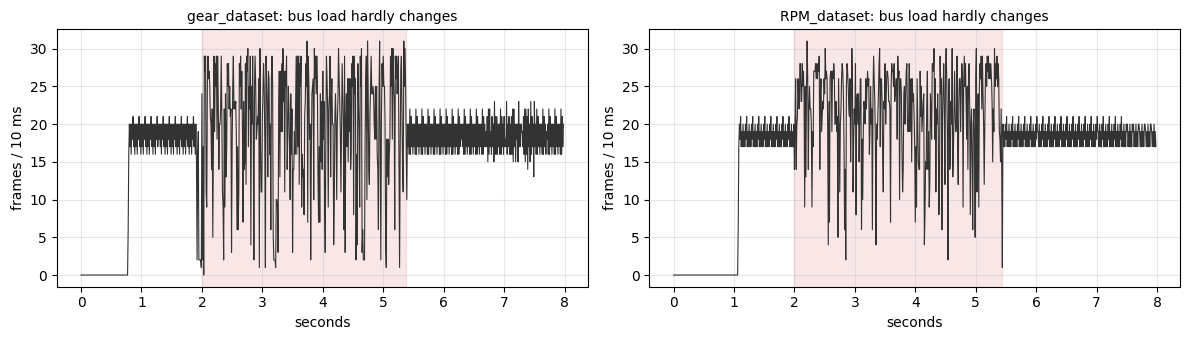

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

for ax, name in zip(axes, ["gear_dataset", "RPM_dataset"]):
    d = caps[name]
    ts, lab = d["ts"], d["label"]
    first = np.flatnonzero(lab != 0)[0]
    t0 = ts[first] - 2.0
    sl = slice(*np.searchsorted(ts, [t0, t0 + 8.0]))
    tw, lw = ts[sl] - t0, lab[sl]
    edges = np.arange(0, 8.0, 0.010)
    rate, _ = np.histogram(tw, bins=edges)
    ax.plot(edges[:-1], rate, lw=0.8, color="#333")
    atk_t = tw[lw != 0]
    if len(atk_t):
        ax.axvspan(atk_t.min(), atk_t.max(), color="#d95f5f", alpha=0.15)
    ax.set_title(f"{name}: bus load hardly changes", fontsize=10)
    ax.set_xlabel("seconds")
    ax.set_ylabel("frames / 10 ms")

plt.tight_layout()
plt.show()

### 4c. Per-ID timing: how spoofing gives itself away

Real ECUs are periodic. `0x316` (RPM) goes out every ~10 ms, like a metronome.
An attacker injecting the same ID every 1 ms does not replace those frames --
they are **added**, so that ID now arrives 10x too often.

That is `period_ratio = dt_same_id / learned_period_for_that_id`. Around 1.0
means on schedule; far below 1.0 means something extra is on the bus.

ID 0x316 inter-arrival gap, median:
  normal frames     9.812 ms   (n=216,333)
  injected frames   1.149 ms   (n=654,897)
  ratio               8.5x faster


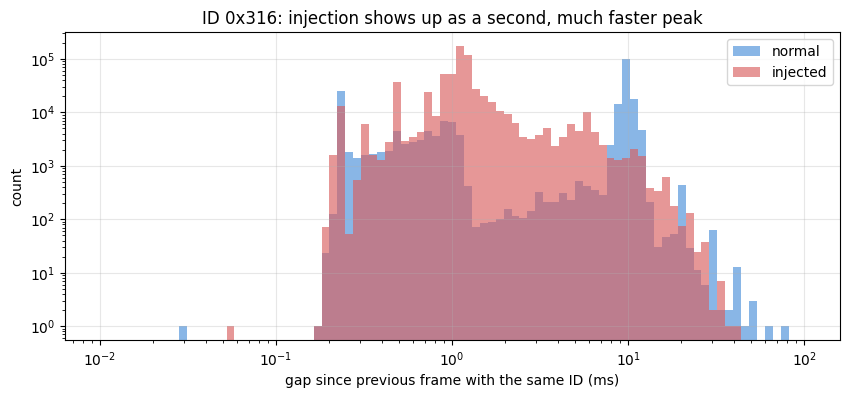

In [9]:
d = caps["RPM_dataset"]
ts, cid, lab = d["ts"], d["can_id"], d["label"]
TARGET = 0x316

m = cid == TARGET
t_id, l_id = ts[m], lab[m]
gaps = np.diff(t_id) * 1000.0           # ms
g_lab = l_id[1:]

clean = gaps[g_lab == 0]
inj = gaps[g_lab != 0]
print(f"ID 0x{TARGET:03X} inter-arrival gap, median:")
print(f"  normal frames   {np.median(clean):7.3f} ms   (n={len(clean):,})")
print(f"  injected frames {np.median(inj):7.3f} ms   (n={len(inj):,})")
print(f"  ratio           {np.median(clean)/np.median(inj):7.1f}x faster")

fig, ax = plt.subplots()
bins = np.logspace(-2, 2, 90)
ax.hist(clean, bins=bins, alpha=0.65, label="normal", color="#4a90d9")
ax.hist(inj, bins=bins, alpha=0.65, label="injected", color="#d95f5f")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("gap since previous frame with the same ID (ms)")
ax.set_ylabel("count")
ax.set_title(f"ID 0x{TARGET:03X}: injection shows up as a second, much faster peak")
ax.legend()
plt.show()

### 4d. Fuzzy: IDs the car has never used

Fuzzy sprays random IDs. A real Sonata only ever uses a few dozen. So simply
asking "have I ever seen this ID before?" is a strong signal -- and it is free,
because we already need the per-ID table.

It is also the **fixed-memory guarantee**: the firmware refuses to allocate a
slot for an ID it does not know, so spraying random IDs cannot exhaust its RAM.
The absence of a slot *is* the feature.

In [10]:
const = F.Constants.load(ROOT / "results" / "constants.json")
known = set(const.known_ids)
print(f"known IDs learned from training normal traffic: {len(known)}")

print(f"\n{'capture':<18} {'unique IDs':>11} {'unknown-ID frames':>19}")
for name, d in caps.items():
    cid = d["can_id"]
    unk = ~np.isin(cid, list(known))
    print(f"{name:<18} {len(np.unique(cid)):>11,} "
          f"{unk.sum():>13,} ({100*unk.mean():5.2f}%)")

d = caps["Fuzzy_dataset"]
cid, lab = d["can_id"], d["label"]
unk = ~np.isin(cid, list(known))
print(f"\nFuzzy capture:")
print(f"  injected frames using an UNKNOWN id: "
      f"{100*unk[lab != 0].mean():.1f}%")
print(f"  normal   frames using an UNKNOWN id: "
      f"{100*unk[lab == 0].mean():.2f}%")

known IDs learned from training normal traffic: 38

capture             unique IDs   unknown-ID frames
DoS_dataset                 27       587,521 (16.03%)
Fuzzy_dataset            2,048       482,491 (12.57%)


gear_dataset                26             0 ( 0.00%)
normal_run_data             27             0 ( 0.00%)
RPM_dataset                 26             0 ( 0.00%)

Fuzzy capture:
  injected frames using an UNKNOWN id: 98.1%
  normal   frames using an UNKNOWN id: 0.00%


## 5. Burst structure -- and the second bug this found

The detection-delay metric first reported **45,329 bursts** with a 0.000 ms
median delay. Nonsense: HCRL documents 3-5 second bursts.

The mistake was grouping bursts by *contiguous runs of the attack label*. During
a campaign, legitimate frames keep arriving and interleave with injected ones,
so the label alternates frame by frame. Each flip started a "new burst".

Measure the gap distribution and the right grouping rule falls out.

In [11]:
ts, lab = caps["RPM_dataset"]["ts"], caps["RPM_dataset"]["label"]
atk = np.flatnonzero(lab != 0)
gaps = np.diff(ts[atk])

print("gaps between consecutive INJECTED frames (ms):")
for q in (50, 90, 99, 99.9):
    print(f"  p{q:<5} {1000*np.percentile(gaps, q):10.3f}")
print(f"  max    {1000*gaps.max():10.3f}")
print(f"\n  gaps longer than 0.5 s: {(gaps > 0.5).sum()}")
print("  -> a clean bimodal split: sub-millisecond inside a burst,")
print("     seconds between bursts. 0.5 s is nowhere near either mode.")

breaks = np.flatnonzero(gaps > 0.5) + 1
groups = np.split(atk, breaks)
durs = [ts[g[-1]] - ts[g[0]] for g in groups]
print(f"\nregrouped: {len(groups)} bursts, median duration {np.median(durs):.3f} s")
print("HCRL documents 3-5 s bursts -- an independent check that the")
print("grouping is now right, since we never used that number to tune it.")

gaps between consecutive INJECTED frames (ms):
  p50         1.163
  p90         2.332
  p99        10.285
  p99.9      19.649
  max      3042.013

  gaps longer than 0.5 s: 300
  -> a clean bimodal split: sub-millisecond inside a burst,
     seconds between bursts. 0.5 s is nowhere near either mode.

regrouped: 301 bursts, median duration 3.458 s
HCRL documents 3-5 s bursts -- an independent check that the
grouping is now right, since we never used that number to tune it.


## 6. The 16 features, and why each one is there

`features.py` is the single source of truth; the C++ in
`firmware/esp32/src/features.h` is a line-for-line port, and
`tests/test_parity.py` compiles that header and checks both agree on real frames.

| # | feature | catches | why |
|---|---------|---------|-----|
| 0 | `can_id_norm` | - | which ID, scaled to [0,1] |
| 1 | `is_known_id` | **Fuzzy** | the car has never used this ID |
| 2 | `dlc_norm` | Fuzzy | odd payload lengths |
| 3-10 | `b0..b7` | Gear, RPM | the spoofed *value* itself |
| 11 | `dt_prev` | DoS | gap since any frame |
| 12 | `dt_same_id` | Gear, RPM | gap since this ID |
| 13 | `period_ratio` | Gear, RPM | this ID vs its learned schedule |
| 14 | `payload_change` | Gear, RPM | bits flipped vs this ID's last payload |
| 15 | `bus_rate` | **DoS** | frames in the last 10 ms |

All 16 come from **one frame plus a small fixed table** -- no window of history
to buffer, so the device can answer on the frame it just received.

In [12]:
# Which features actually separate which attack? Compare each attack's median
# feature value against normal traffic's, in units of normal's spread.
d = caps["RPM_dataset"]
sub = slice(0, 400_000)
X = F.transform(d["ts"][sub], d["can_id"][sub],
                d["dlc"][sub], d["data"][sub], const)
y = d["label"][sub]

norm = X[y == 0]
spread = np.maximum(norm.std(axis=0), 1e-6)
sep = np.abs(X[y != 0].mean(axis=0) - norm.mean(axis=0)) / spread

order = np.argsort(sep)[::-1]
print("RPM spoofing -- feature separation (|mean diff| / normal std):\n")
for j in order[:8]:
    bar = "#" * int(min(sep[j], 6) * 8)
    print(f"  {F.FEATURE_NAMES[j]:<14} {sep[j]:6.2f}  {bar}")

RPM spoofing -- feature separation (|mean diff| / normal std):

  byte7            3.05  ########################
  byte3            2.04  ################
  period_ratio     1.95  ###############
  dt_same_id       0.91  #######
  bus_rate         0.48  ###
  byte6            0.46  ###
  byte5            0.37  ##
  dt_prev          0.30  ##


## 7. What we concluded

1. **Parse carefully.** Two different file formats, and a flag column whose
   position depends on DLC. Pinned by `tests/test_parse.py`.
2. **Split by time, per region.** The clean tail would otherwise have handed us
   a meaningless 99.996%.
3. **Different attacks need different features.** DoS is a rate anomaly, Fuzzy
   an unknown-ID anomaly, Gear/RPM a per-ID timing anomaly. One feature set
   covers all three because the per-ID table is cheap.
4. **Learn periods from normal frames only.** A spoofed 1 ms interval would drag
   the median period down and switch `period_ratio` off entirely.
5. **Group bursts by time gap, not label contiguity.**

### Honest limitation found here

Inside a burst, legitimate frames of the spoofed ID look *more* anomalous than
the injected ones -- they arrive right after an injected frame, so their
`period_ratio` is tiny. Timing alone therefore cannot say *which* frame was
injected; the model has to use the payload. That is measured in
`securecan.evaluate --unseen` and it is why an **unseen** attack type is not
detected. It is reported in the README rather than hidden.

Next: `python -m securecan.train` then `python -m securecan.evaluate`.